In [15]:
import os
import warnings
from pathlib import Path

import pandas as pd
import numpy as np
import scanpy as sc
import anndata as ad
import hdf5plugin
import matplotlib.pyplot as plt
import seaborn as sns
import h5py

import squidpy as sq
import spatialdata as sd
from spatialdata_io import xenium
#import spatialdata_io as sio
import spatialdata_plot

### default 

In [16]:
def print_sample_qc(adata):
    ## Print some stats
    cprobes = (
        adata.obs["control_probe_counts"].sum() / adata.obs["total_counts"].sum() * 100
    )
    cwords = (
        adata.obs["control_codeword_counts"].sum() / adata.obs["total_counts"].sum() * 100
    )
    print(f"Negative DNA probe count % : {cprobes}")
    print(f"Negative decoding count % : {cwords}")
    
    fig, axs = plt.subplots(1, 4, figsize=(15, 4))

    axs[0].set_title("Total transcripts per cell")
    sns.histplot(
        adata.obs["total_counts"],
        kde=False,
        ax=axs[0],
    )
    
    axs[1].set_title("Unique transcripts per cell")
    sns.histplot(
        adata.obs["n_genes_by_counts"],
        kde=False,
        ax=axs[1],
    )
    
    
    axs[2].set_title("Area of segmented cells")
    sns.histplot(
        adata.obs["cell_area"],
        kde=False,
        ax=axs[2],
    )
    
    axs[3].set_title("Nucleus ratio")
    sns.histplot(
        adata.obs["nucleus_area"] / adata.obs["cell_area"],
        kde=False,
        ax=axs[3],
    )
    plt.show()

In [39]:
xenium_path = '/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/vk348/rawdata/thymus/xenium/'
xenium_files = pd.Series(os.listdir(xenium_path))
xenium_files = xenium_files[xenium_files != "A72-THY-0-FFPE-1"]

In [40]:
xenium_files

0    A45-THY-0-FFPE-1
1      Z16-THY-0-FF-1
2    A67-THY-0-FFPE-1
4      Z17-THY-0-FF-1
5    A70-THY-0-FFPE-2
dtype: object

A45-THY-0-FFPE-1


/tmp/ipykernel_95787/421608556.py:9: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  sdata = xenium(xenium_path + file)
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


WARNING  The `feature_key` column feature_name is categorical with unknown categories. Please ensure the categories
         are known before calling `PointsModel.parse()` to avoid significant performance implications due to the   
         need for dask to compute the categories. If you did not use PointsModel.parse() explicitly in your code   
         (e.g. this message is coming from a reader in `spatialdata_io`), please report this finding.              


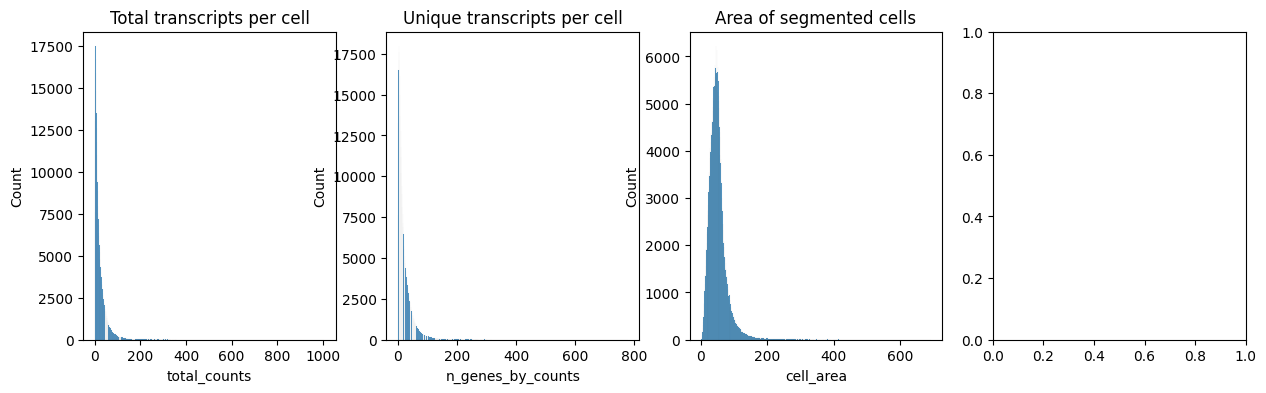

Total number of cells: 371205
Fraction of cells with at least 50 genes detected:0.102
Z16-THY-0-FF-1


/tmp/ipykernel_95787/421608556.py:9: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  sdata = xenium(xenium_path + file)
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


WARNING  The `feature_key` column feature_name is categorical with unknown categories. Please ensure the categories
         are known before calling `PointsModel.parse()` to avoid significant performance implications due to the   
         need for dask to compute the categories. If you did not use PointsModel.parse() explicitly in your code   
         (e.g. this message is coming from a reader in `spatialdata_io`), please report this finding.              


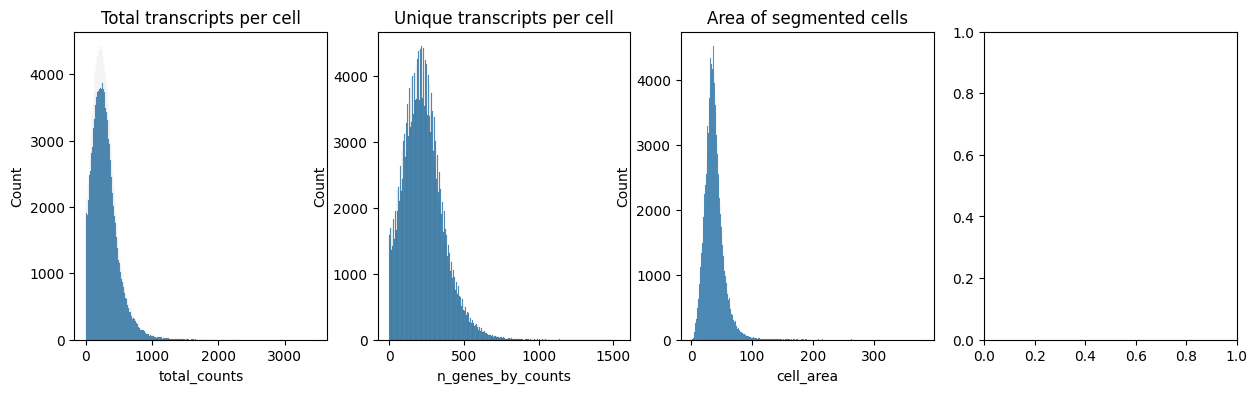

Total number of cells: 230283
Fraction of cells with at least 50 genes detected:0.936
A67-THY-0-FFPE-1


/tmp/ipykernel_95787/421608556.py:9: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  sdata = xenium(xenium_path + file)
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


WARNING  The `feature_key` column feature_name is categorical with unknown categories. Please ensure the categories
         are known before calling `PointsModel.parse()` to avoid significant performance implications due to the   
         need for dask to compute the categories. If you did not use PointsModel.parse() explicitly in your code   
         (e.g. this message is coming from a reader in `spatialdata_io`), please report this finding.              


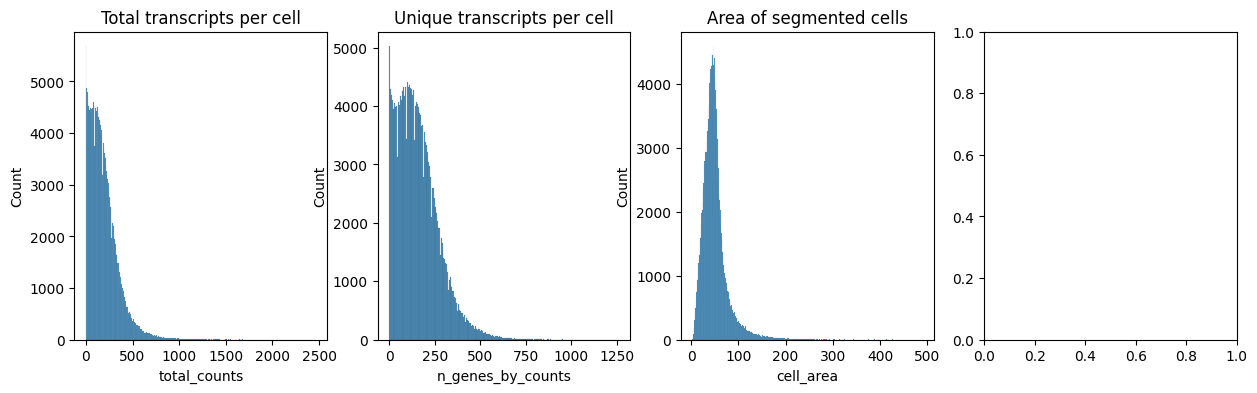

Total number of cells: 238242
Fraction of cells with at least 50 genes detected:0.826
Z17-THY-0-FF-1


/tmp/ipykernel_95787/421608556.py:9: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  sdata = xenium(xenium_path + file)
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


WARNING  The `feature_key` column feature_name is categorical with unknown categories. Please ensure the categories
         are known before calling `PointsModel.parse()` to avoid significant performance implications due to the   
         need for dask to compute the categories. If you did not use PointsModel.parse() explicitly in your code   
         (e.g. this message is coming from a reader in `spatialdata_io`), please report this finding.              


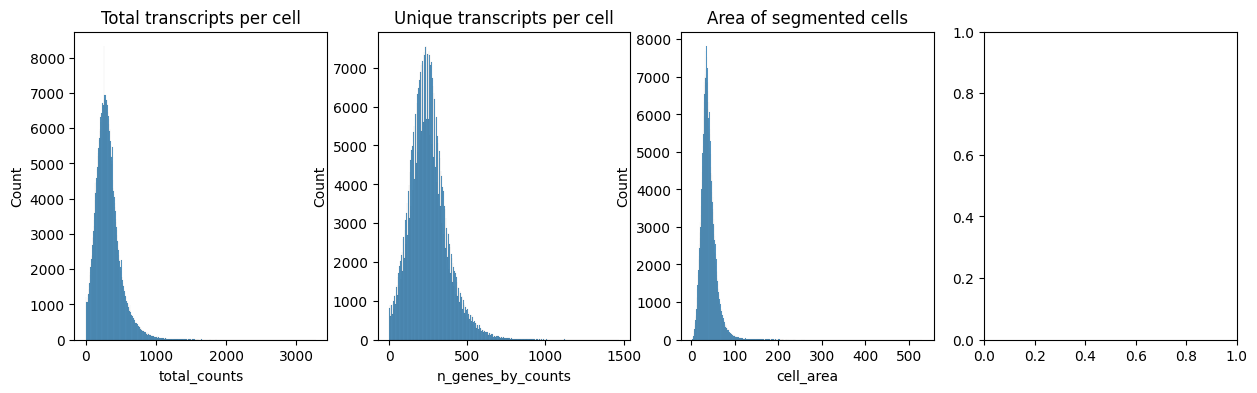

Total number of cells: 483767
Fraction of cells with at least 50 genes detected:0.974
A70-THY-0-FFPE-2


/tmp/ipykernel_95787/421608556.py:9: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  sdata = xenium(xenium_path + file)
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


WARNING  The `feature_key` column feature_name is categorical with unknown categories. Please ensure the categories
         are known before calling `PointsModel.parse()` to avoid significant performance implications due to the   
         need for dask to compute the categories. If you did not use PointsModel.parse() explicitly in your code   
         (e.g. this message is coming from a reader in `spatialdata_io`), please report this finding.              


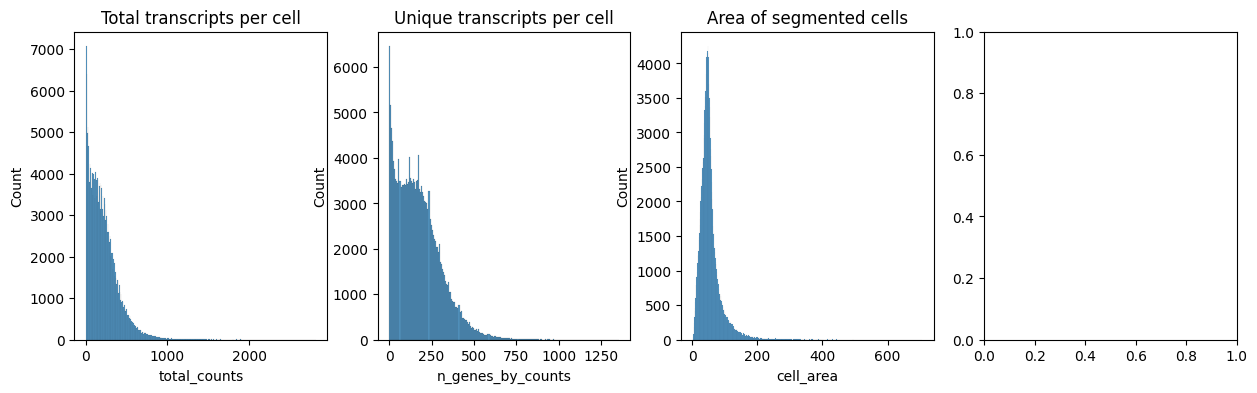

Total number of cells: 194146
Fraction of cells with at least 50 genes detected:0.815


In [41]:
adata_list_def = []

for file in xenium_files:
    ## Extract metadata from name
    sample_ID = file
    print(sample_ID)

    ## Read object and keep adata
    sdata = xenium(xenium_path + file)
    adata = sdata.tables["table"]

    ## Update metadata
    adata.obs.index = sample_ID + '-' + pd.Series(adata.obs['cell_id'].tolist())
    adata.obs['sample_barcode'] = adata.obs_names.tolist()
    adata.obs['sample_ID'] = sample_ID

    ## Standard qc
    sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

    ## Print some sample QC and show some plots
    print_sample_qc(adata)

    print('Total number of cells: ' + str(adata.obs.shape[0]))
    print('Fraction of cells with at least 50 genes detected:' + str(np.round((sum(adata.obs['n_genes_by_counts'] >= 50) /adata.obs.shape[0]), decimals=3))) 
    
    adata_list_def.append(adata)

In [42]:
adata_default = ad.concat(
    adata_list_def,
    axis=0,          # concatenate cells
    join="outer"    # union of genes 
)

In [43]:
adata_default

AnnData object with n_obs × n_vars = 1517643 × 5001
    obs: 'cell_id', 'transcript_counts', 'control_probe_counts', 'genomic_control_counts', 'control_codeword_counts', 'unassigned_codeword_counts', 'deprecated_codeword_counts', 'total_counts', 'cell_area', 'nucleus_area', 'nucleus_count', 'segmentation_method', 'region', 'z_level', 'cell_labels', 'sample_barcode', 'sample_ID', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes'
    obsm: 'spatial'

### proseg

In [22]:
def print_sample_qc(adata):
    ## Print some stats
    
    fig, axs = plt.subplots(1, 4, figsize=(15, 4))

    axs[0].set_title("Total transcripts per cell")
    sns.histplot(
        adata.obs["total_counts"],
        kde=False,
        ax=axs[0],
    )
    
    axs[1].set_title("Unique transcripts per cell")
    sns.histplot(
        adata.obs["n_genes_by_counts"],
        kde=False,
        ax=axs[1],
    )
    
    
    axs[2].set_title("Area of segmented cells")
    sns.histplot(
        adata.obs["cell_area"],
        kde=False,
        ax=axs[2],
    )
    
    plt.show()

In [27]:
xenium_path = '/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/proseg_results/'
xenium_files = pd.Series(os.listdir(xenium_path))
xenium_files_filtered = xenium_files[~xenium_files.str.contains('ipynb_checkpoints')]

In [29]:
xenium_files_filtered = ['A45','Z16','A70','Z17','A67']

A45


/tmp/ipykernel_95787/2981322425.py:10: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdata = sd.read_zarr(xenium_path + file + "/sdata.zarr")
/tmp/ipykernel_95787/2981322425.py:17: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  polys["cell_area"] = polys.geometry.area


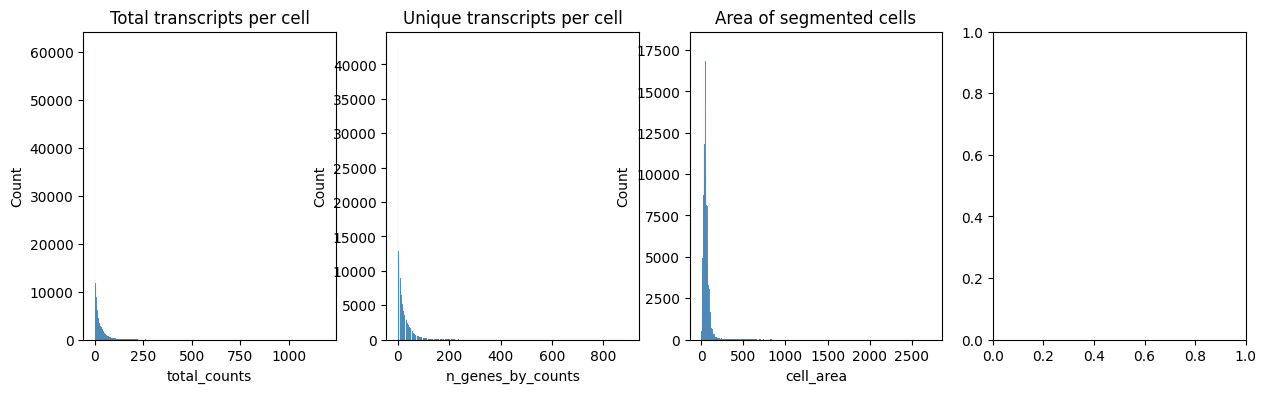

Total number of cells: 348215
Fraction of cells with at least 50 genes detected:0.126
Z16


/tmp/ipykernel_95787/2981322425.py:10: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdata = sd.read_zarr(xenium_path + file + "/sdata.zarr")
/tmp/ipykernel_95787/2981322425.py:17: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  polys["cell_area"] = polys.geometry.area


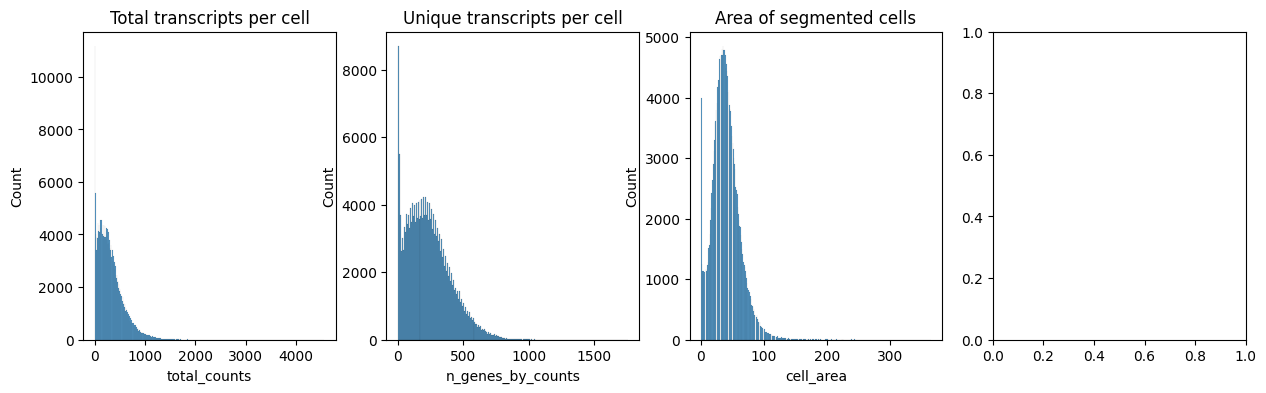

Total number of cells: 220195
Fraction of cells with at least 50 genes detected:0.872
A70


/tmp/ipykernel_95787/2981322425.py:10: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdata = sd.read_zarr(xenium_path + file + "/sdata.zarr")
/tmp/ipykernel_95787/2981322425.py:17: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  polys["cell_area"] = polys.geometry.area


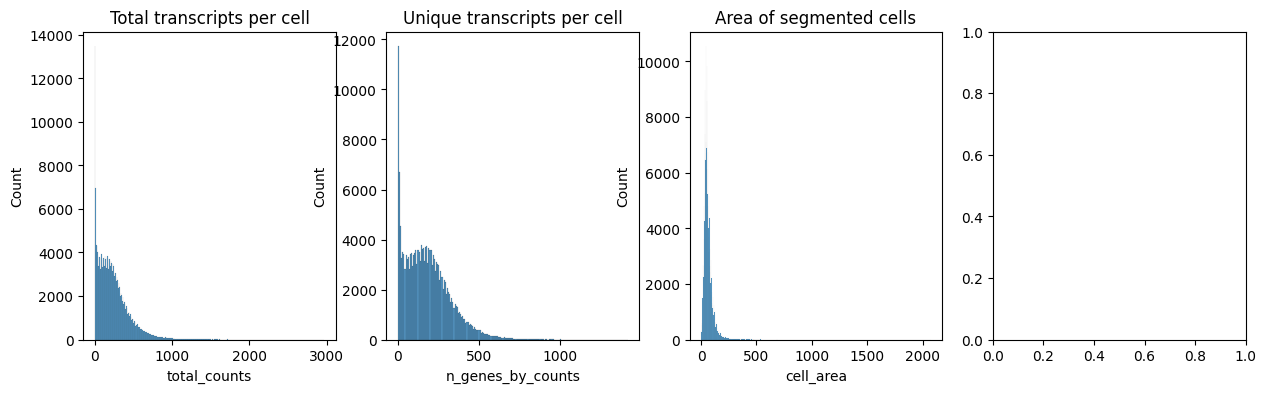

Total number of cells: 189925
Fraction of cells with at least 50 genes detected:0.803
Z17


/tmp/ipykernel_95787/2981322425.py:10: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdata = sd.read_zarr(xenium_path + file + "/sdata.zarr")
/tmp/ipykernel_95787/2981322425.py:17: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  polys["cell_area"] = polys.geometry.area


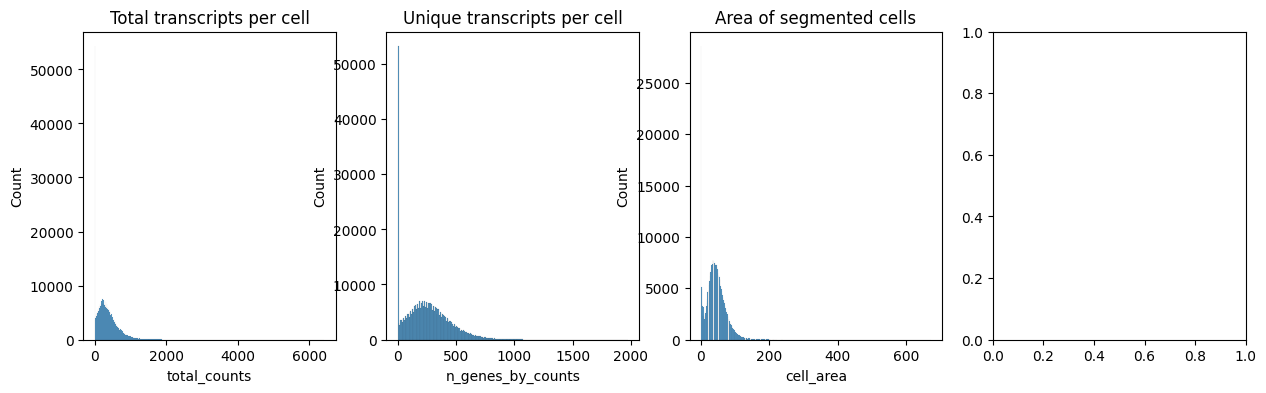

Total number of cells: 462507
Fraction of cells with at least 50 genes detected:0.839
A67


/tmp/ipykernel_95787/2981322425.py:10: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  sdata = sd.read_zarr(xenium_path + file + "/sdata.zarr")
/tmp/ipykernel_95787/2981322425.py:17: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  polys["cell_area"] = polys.geometry.area


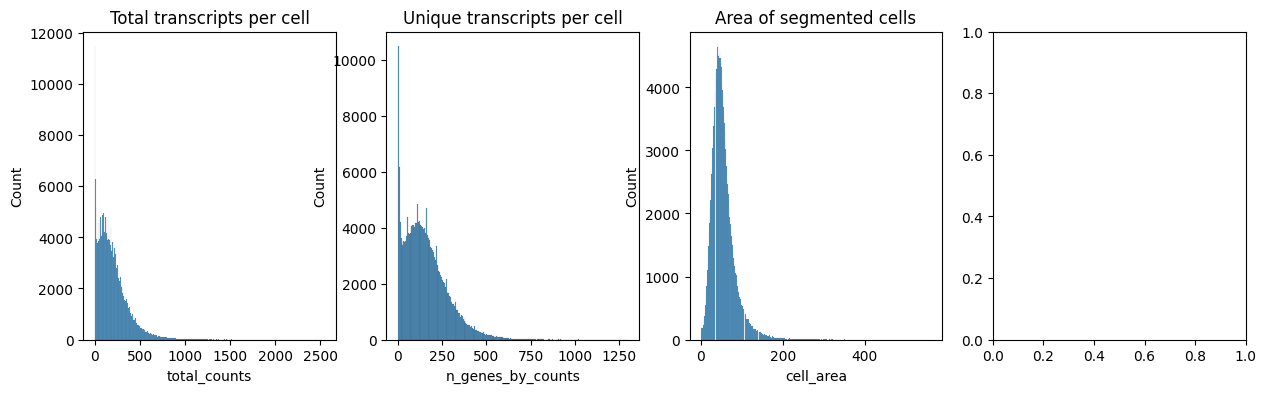

Total number of cells: 233796
Fraction of cells with at least 50 genes detected:0.808


In [30]:
adata_list = []

for file in xenium_files_filtered:
    ## Extract metadata from name
    sample_ID = file
    print(sample_ID)
    
    # 1. Load the count matrix generated by Proseg
    # This reads the counts.mtx.gz and the genes/barcodes if present
    sdata = sd.read_zarr(xenium_path + file + "/sdata.zarr")
    adata = sdata.tables["table"]

    adata.var_names = adata.var['gene']
    
    polys = sdata.shapes["cell_boundaries"]
    # compute area
    polys["cell_area"] = polys.geometry.area
    polys.index = polys.index.astype(str)
    # add to AnnData table
        
    adata.obs["cell_area"] = polys["cell_area"]

    ## Update metadata
    adata.obs.index = sample_ID + '-' + adata.obs['cell'].astype(str)
    adata.obs['sample_barcode'] = adata.obs_names.tolist()
    adata.obs['sample_ID'] = sample_ID

    ## Standard qc
    sc.pp.calculate_qc_metrics(adata, percent_top=(10, 20, 50, 150), inplace=True)

    ## Print some sample QC and show some plots
    print_sample_qc(adata)

    print('Total number of cells: ' + str(adata.obs.shape[0]))
    print('Fraction of cells with at least 50 genes detected:' + str(np.round((sum(adata.obs['n_genes_by_counts'] >= 50) /adata.obs.shape[0]), decimals=3))) 


    adata_list.append(adata)

In [31]:
adata_proseg = ad.concat(
    adata_list,
    axis=0,          # concatenate cells
    join="outer"    # union of genes 
)

In [32]:
adata_proseg

AnnData object with n_obs × n_vars = 1454638 × 5001
    obs: 'cell', 'original_cell_id', 'centroid_x', 'centroid_y', 'centroid_z', 'component', 'volume', 'surface_area', 'scale', 'region', 'cell_area', 'sample_barcode', 'sample_ID', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'pct_counts_in_top_10_genes', 'pct_counts_in_top_20_genes', 'pct_counts_in_top_50_genes', 'pct_counts_in_top_150_genes'
    obsm: 'spatial'

### comparison

In [44]:
metrics = pd.DataFrame({
    "Metric": ["Total Cells", "Median Transcripts/Cell", "Median Genes/Cell", "Total Transcripts Assigned"],
    "Default": [
        adata_default.n_obs,
        adata_default.obs['total_counts'].median(),
        adata_default.obs['n_genes_by_counts'].median(),
        adata_default.X.sum()
    ],
    "Proseg": [
        adata_proseg.n_obs,
        adata_proseg.obs['total_counts'].median(),
        adata_proseg.obs['n_genes_by_counts'].median(),
        adata_proseg.X.sum()
    ]
})
print(metrics)

                       Metric      Default       Proseg
0                 Total Cells    1517643.0    1454638.0
1     Median Transcripts/Cell        174.0        149.0
2           Median Genes/Cell        154.0        130.0
3  Total Transcripts Assigned  313414656.0  323987642.0


Proseg typically increases the Median Transcripts/Cell because it expands boundaries to include legitimate cytosolic transcripts that simple nuclear expansion cuts off.

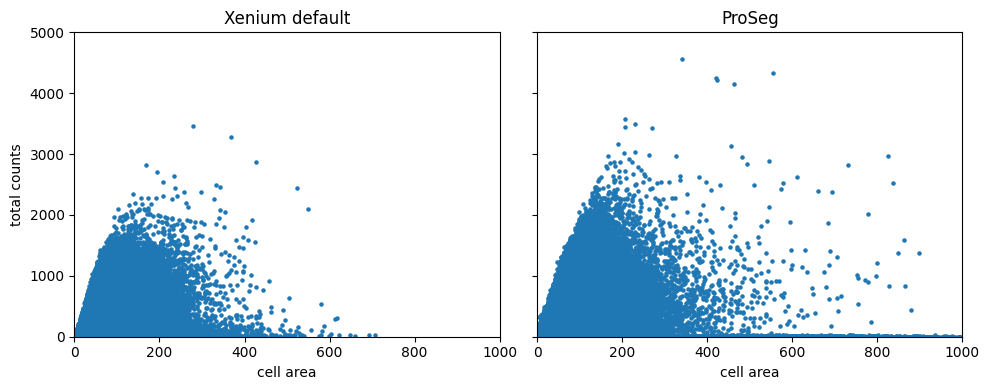

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True)

# Xenium default
axes[0].scatter(
    adata_default.obs['cell_area'],
    adata_default.obs['total_counts'],
    s=5
)
axes[0].set_title("Xenium default")
axes[0].set_xlabel("cell area")
axes[0].set_ylabel("total counts")
axes[0].set_xlim(0, 1000)
axes[0].set_ylim(0, 5000)

# ProSeg
axes[1].scatter(
    adata_proseg.obs['cell_area'],
    adata_proseg.obs['total_counts'],
    s=5
)
axes[1].set_title("ProSeg")
axes[1].set_xlabel("cell area")
axes[1].set_xlim(0, 1000)
axes[1].set_ylim(0, 5000)

plt.tight_layout()
plt.show()

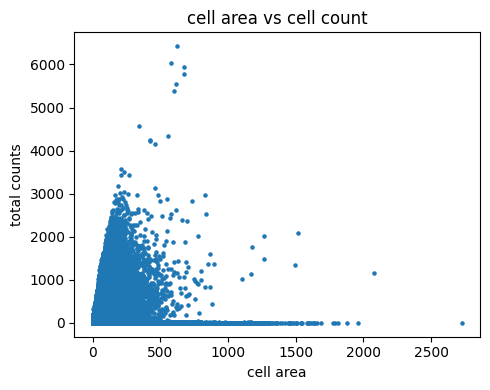

In [46]:
plt.figure(figsize=(5, 4))
plt.scatter(adata_proseg.obs['cell_area'],adata_proseg.obs['total_counts'],s=5)
plt.xlabel("cell area")
plt.ylabel("total counts")
plt.title("cell area vs cell count")
plt.tight_layout()
plt.show()

# sample2sample comparison

In [ ]:
import spatialdata as sd
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from spatialdata_io import xenium
import os

In [53]:
xenium_path = '/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/vk348/rawdata/thymus/xenium/'

xenium_files = ['A45-THY-0-FFPE-1',
                'Z16-THY-0-FF-1',
                'A67-THY-0-FFPE-1',
                'Z17-THY-0-FF-1',
                'A70-THY-0-FFPE-2']


In [48]:
proseg_path = '/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/proseg_results/'

proseg_files = ['A45',
                'Z16',
                'A67',
                'Z17',
                'A70']

In [49]:
def get_segmentation_stats(sdata, table_name, label):
    """Extracts core metrics from a SpatialData table."""
    if table_name not in sdata.tables:
        return None
    
    adata = sdata.tables[table_name]
    
    if (label == 'Proseg'):
        
        polys = sdata.shapes["cell_boundaries"]
        # compute area
        polys["cell_area"] = polys.geometry.area
        polys.index = polys.index.astype(str)
        # add to AnnData table
        
        adata.obs["cell_area"] = polys["cell_area"]
    
    # Calculate basic counts
    tpc = adata.X.sum(axis=1).A1 if hasattr(adata.X, "toarray") else adata.X.sum(axis=1)
    gpc = (adata.X > 0).sum(axis=1).A1 if hasattr(adata.X, "toarray") else (adata.X > 0).sum(axis=1)
    
    # Calculate area (assuming 'cell_area' exists in obs, common in XOA/Proseg)
    # If not present, you may need to calculate it from the shapes
    area = adata.obs.get('cell_area', np.nan)
    
    df = pd.DataFrame({
        'TPC': tpc,
        'GPC': gpc,
        'Area': area,
        'Density': tpc / area,
        'Method': label
    })
    return df

In [54]:
all_results = []

for i in range(5):
    print(f"Processing {proseg_files[i]}...")
    
    try:
        s_xoa = xenium(xenium_path + xenium_files[i])
        s_pro = sd.read_zarr(proseg_path + proseg_files[i] + '/sdata.zarr')
        
        df_xoa = get_segmentation_stats(s_xoa, "table", "XOA (Default)")
        df_pro = get_segmentation_stats(s_pro, "table", "Proseg")
        
        if df_xoa is not None and df_pro is not None:
            df_combined = pd.concat([df_xoa, df_pro])
            df_combined['Sample'] = proseg_files[i]
            all_results.append(df_combined)
            
    except Exception as e:
        print(f"Error loading {proseg_files[i]}: {e}")

# Aggregate all data
full_df = pd.concat(all_results)



Processing A45...


/tmp/ipykernel_95787/2071149274.py:7: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  s_xoa = xenium(xenium_path + xenium_files[i])
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


WARNING  The `feature_key` column feature_name is categorical with unknown categories. Please ensure the categories
         are known before calling `PointsModel.parse()` to avoid significant performance implications due to the   
         need for dask to compute the categories. If you did not use PointsModel.parse() explicitly in your code   
         (e.g. this message is coming from a reader in `spatialdata_io`), please report this finding.              


/tmp/ipykernel_95787/2071149274.py:8: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  s_pro = sd.read_zarr(proseg_path + proseg_files[i] + '/sdata.zarr')
/tmp/ipykernel_95787/3145645568.py:12: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  polys["cell_area"] = polys.geometry.area


Processing Z16...


/tmp/ipykernel_95787/2071149274.py:7: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  s_xoa = xenium(xenium_path + xenium_files[i])
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


... (10 outputs left out)

Processing A70...


/tmp/ipykernel_95787/2071149274.py:7: DeprecationWarning: The default value of `cells_as_circles` will change to `False` in the next release. Please pass `True` explicitly to maintain the current behavior.
  s_xoa = xenium(xenium_path + xenium_files[i])
/rfs/project/rfs-iCNyzSAaucw/nd590/miniconda3/envs/napari_env/lib/python3.12/functools.py:912: ImplicitModificationWarning: Transforming to str index.
  return dispatch(args[0].__class__)(*args, **kw)


WARNING  The `feature_key` column feature_name is categorical with unknown categories. Please ensure the categories
         are known before calling `PointsModel.parse()` to avoid significant performance implications due to the   
         need for dask to compute the categories. If you did not use PointsModel.parse() explicitly in your code   
         (e.g. this message is coming from a reader in `spatialdata_io`), please report this finding.              


/tmp/ipykernel_95787/2071149274.py:8: UserWarning: SpatialData is not stored in the most current format. If you want to use Zarr v3, please write the store to a new location using `sdata.write()`.
  s_pro = sd.read_zarr(proseg_path + proseg_files[i] + '/sdata.zarr')
/tmp/ipykernel_95787/3145645568.py:12: UserWarning: Geometry is in a geographic CRS. Results from 'area' are likely incorrect. Use 'GeoSeries.to_crs()' to re-project geometries to a projected CRS before this operation.

  polys["cell_area"] = polys.geometry.area


In [ ]:
full_df.to_pickle('/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/metadata/segmentation_comp.pkl')

In [ ]:
full_df = pd.read_pickle('/home/nd590/rfs/rfs-teichlab-nfs-iCNyzSAaucw/nd590/projects/aging/metadata/segmentation_comp.pkl')

In [55]:
full_df

,TPC,GPC,Area,Density,Method,Sample
0,63.0,53,56.490471,1.115232,XOA (Default),A45
1,201.0,168,64.708909,3.106218,XOA (Default),A45
2,0.0,0,48.994533,0.000000,XOA (Default),A45
3,201.0,174,36.757189,5.468318,XOA (Default),A45
4,275.0,229,58.161252,4.728234,XOA (Default),A45
...,...,...,...,...,...,...
189920,46.0,36,89.000000,0.516854,Proseg,A70
189921,161.0,139,56.000000,2.875000,Proseg,A70
189922,171.0,137,121.000000,1.413223,Proseg,A70
189923,14.0,14,54.000000,0.259259,Proseg,A70


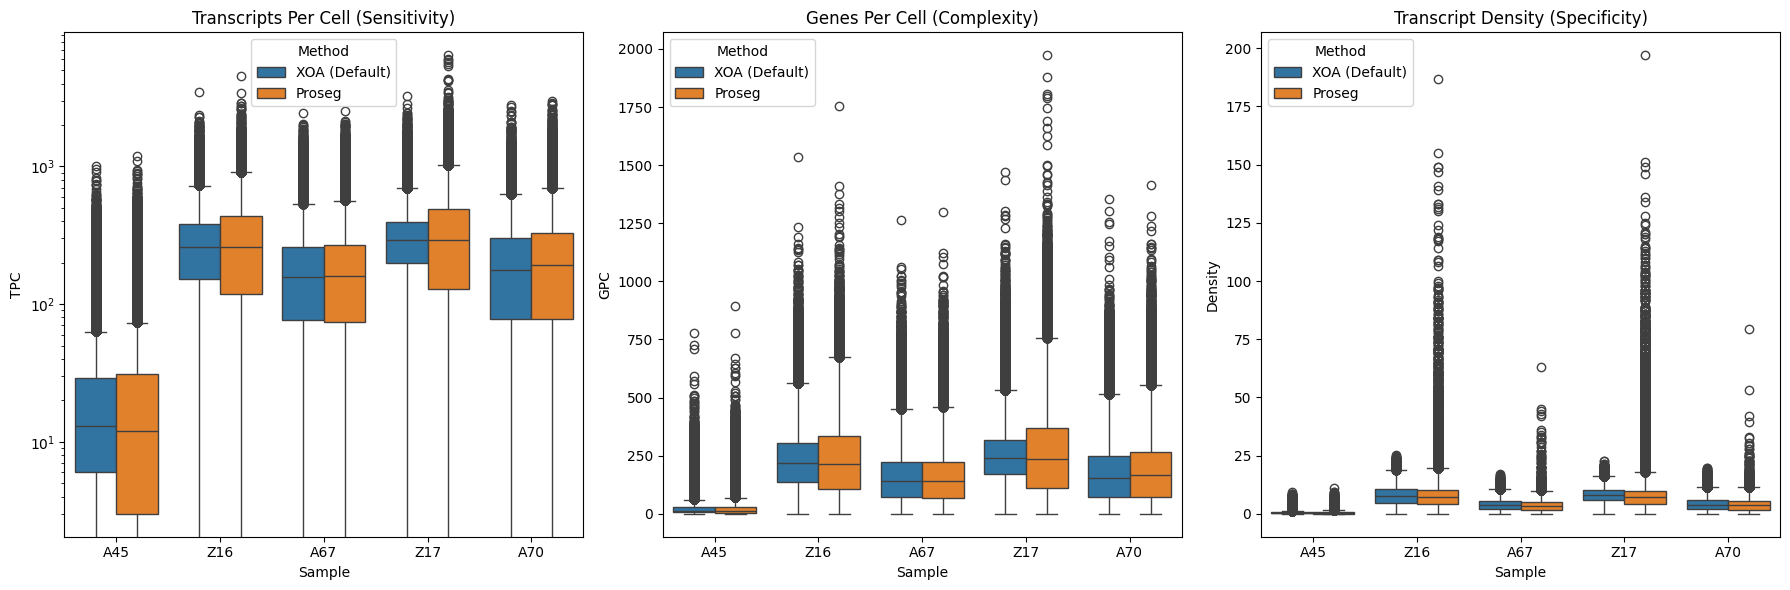

In [56]:
# --- VISUALIZATION ---
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

# 1. Transcripts Per Cell Comparison
sns.boxplot(data=full_df, x='Sample', y='TPC', hue='Method', ax=axes[0])
axes[0].set_title("Transcripts Per Cell (Sensitivity)")
axes[0].set_yscale('log')

# 2. Genes Per Cell Comparison
sns.boxplot(data=full_df, x='Sample', y='GPC', hue='Method', ax=axes[1])
axes[1].set_title("Genes Per Cell (Complexity)")

# 3. Transcript Density (TPC / Area)
# Higher density is better; lower density with higher TPC implies "bloated" cells
sns.boxplot(data=full_df, x='Sample', y='Density', hue='Method', ax=axes[2])
axes[2].set_title("Transcript Density (Specificity)")

plt.tight_layout()
plt.show()



In [57]:
# --- SUMMARY TABLE ---
summary = full_df.groupby(['Sample', 'Method']).agg({
    'TPC': 'median',
    'GPC': 'median',
    'Area': 'median'
}).reset_index()
print(summary)

  Sample         Method    TPC    GPC       Area
0    A45         Proseg   12.0   12.0  52.000000
1    A45  XOA (Default)   13.0   13.0  47.007658
2    A67         Proseg  159.0  139.0  49.000000
3    A67  XOA (Default)  158.0  141.0  45.743283
4    A70         Proseg  192.0  165.0  54.000000
5    A70  XOA (Default)  177.0  156.0  48.362346
6    Z16         Proseg  258.0  213.0  38.000000
7    Z16  XOA (Default)  259.0  219.0  35.899220
8    Z17         Proseg  290.0  237.0  42.000000
9    Z17  XOA (Default)  290.0  242.0  37.253908
